IMPORT THE LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report


DATA COLLECTION AND PROCESSING

In [ ]:
#LOAD THE CSV DATA TO A PANDAS DATAFRAME


df=pd.read_csv("/content/drive/MyDrive/heart_disease_data.csv")
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [ ]:
#PRINT FIRST 5 ROWS OF THE DATASET

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
#PRINT LAST 5 ROWS OF THE DATASET

df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0
302,57,0,1,130,236,0,0,174,0,0.0,1,1,2,0


In [ ]:
#NUMBER OF ROWS ANS COLUMNS IN THE DATASET

df.shape

(303, 14)

In [ ]:
#GETTING SOME INFO FROM THE DATA

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [ ]:
#CHECK FOR MISSING VALUES

df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
#GET SOME STATISTICAL MEASURES ABOUT THE DATA

df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
#GET DISTRIBUTION OF TARGET VARIABLE

df['target'].value_counts()

,count
target,
1,165
0,138


1 REPRESENTS DEFECTIVE HEART THAT MEANS PERSON HAS DISEASE

0 REPRESENTS HEALTHY HEART THAT MEANS PERSON HAS NO DISEASE

SPLITTING THE FEATURES AND TARGET

In [ ]:
x=df.drop(["target","age"],axis=1)
y=df["target"]

In [ ]:
x

,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,1,3,145,233,1,0,150,0,2.3,0,0,1
1,1,2,130,250,0,1,187,0,3.5,0,0,2
2,0,1,130,204,0,0,172,0,1.4,2,0,2
3,1,1,120,236,0,1,178,0,0.8,2,0,2
4,0,0,120,354,0,1,163,1,0.6,2,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
298,0,0,140,241,0,1,123,1,0.2,1,0,3
299,1,3,110,264,0,1,132,0,1.2,1,0,3
300,1,0,144,193,1,1,141,0,3.4,1,2,3
301,1,0,130,131,0,1,115,1,1.2,1,1,3


In [ ]:
y

,target
0,1
1,1
2,1
3,1
4,1
...,...
298,0
299,0
300,0
301,0


SPLITTING THE DATA INTO TRAINING DATA AND TEST DATA

In [ ]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)


In [ ]:
print(x.shape,x_train.shape,x_test.shape)

(303, 12) (242, 12) (61, 12)


MODEL TRAINING

LOGISTIC REGRESSION

In [ ]:
model=LogisticRegression()

#TRAINING THE LogisticRegression MODEL WITH THE TRAINING DATA

model.fit(x_train,y_train)

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

MODEL EVALUTION

ACCURACY SCORE

In [ ]:


y_pred=model.predict(x_test)
accuracy=accuracy_score(y_test,y_pred)
accuracy

0.9016393442622951

CONFUSION MATRIX

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
cnf_matrix=confusion_matrix(y_test,y_pred)
cnf_matrix

array([[26,  6],
       [ 0, 29]])

In [ ]:
class_names=["disease","no disease"]

CREATE A HEATMAP

Text(0.5, 23.52222222222222, 'predicted label')

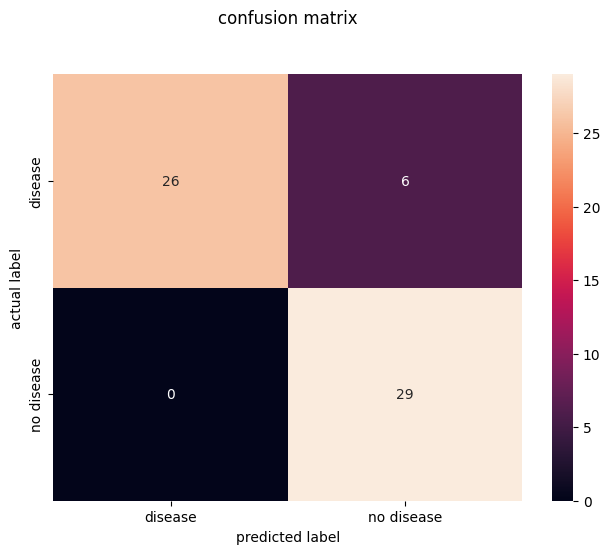

In [ ]:
sns.heatmap(pd.DataFrame(cnf_matrix,index=class_names,columns=class_names),annot=True)
plt.tight_layout()
plt.title("confusion matrix",y=1.1)
plt.ylabel("actual label")
plt.xlabel("predicted label")

CLASSIFICATION REPORT

In [ ]:
from sklearn.metrics import classification_report
target_names=["disease","no disesase"]
print(classification_report(y_test,y_pred,target_names=target_names))

              precision    recall  f1-score   support

     disease       1.00      0.81      0.90        32
 no disesase       0.83      1.00      0.91        29

    accuracy                           0.90        61
   macro avg       0.91      0.91      0.90        61
weighted avg       0.92      0.90      0.90        61



ROC-AUC CURVE

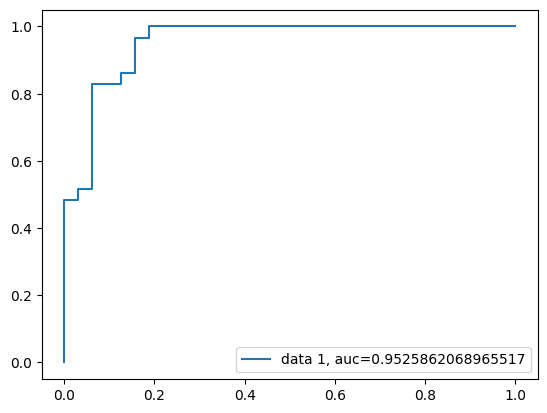

In [ ]:
from sklearn import metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()

DEPLOYMENT OF MODEL  OR  BUILD A PREDICTIVE SYSTEM

In [ ]:
input_data=(1,0,140,239,0,1,160,0,1.2,2,0,2,)

#CHANGE INPUT DATA TO A NUMPY ARRAY

input_data_as_numpy_array=np.asarray(input_data)

#RESHAPE THE NUMPY ARRAY AS WE PREDICTING FOR ONLY ONE INSTANCE

input_data_reshaped=input_data_as_numpy_array.reshape(1,-1)

pre=model.predict(input_data_reshaped)
print(pre)

if(pre[0]==0):
  print("THE PERSON DOES NOT HAVE A HEART DISEASE")
else:
  print("THE PERSON HAS HEART DISEASE")

[1]
THE PERSON HAS HEART DISEASE


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
